# Lab 2 — What Did the Campaign Deliver?
Name: Chen Xinwei (Чень Сіньвей) | Group: KM-42

October 2024: BRAND_A campaign, adults 18–49.

## Setup

Run all cells in order. Version 3 of the course dataset is downloaded automatically. Persons are R and L only. A broadcast day starts at 06:00.

In [ ]:
import importlib.util
import subprocess
import sys
needed = {"kagglehub": "kagglehub", "pyarrow": "pyarrow", "pandas": "pandas",
          "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [p for m, p in needed.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

for frame in [programs, viewings, commercials]:
    for c in ["start_ts", "end_ts"]:
        if c in frame:
            frame[c] = pd.to_datetime(frame[c])
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).dt.normalize()
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]
NETWORKS = BIG + SMALL
pd.set_option("display.max_columns", 15)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})

pw = daily_weights.loc[daily_weights.resp_type.isin(["R", "L"])].copy()
mw = pw.groupby("respondent_id").weight.mean()
age = viewer_attributes.loc[viewer_attributes.attr_id.eq(300)].set_index("respondent_id").value
female = set(viewer_attributes.loc[viewer_attributes.attr_id.eq(202), "respondent_id"])
target_ids = set(age[age.between(18, 49)].index)
w1834_ids = set(age[age.between(18, 34)].index) & female
pw["target"] = pw.respondent_id.isin(target_ids)
universe = pw.groupby("broadcast_date").weight.sum()
target_universe = pw.loc[pw.target].groupby("broadcast_date").weight.sum()
in_tab_n = pw.groupby("broadcast_date").respondent_id.nunique()
monthly_universe = mw.sum()
monthly_target_universe = mw[mw.index.isin(target_ids)].sum()

def answer(text):
    display(Markdown("**Answer:** " + text))

def reach(ids, target=False):
    ids = set(ids)
    if target:
        ids &= target_ids
    denominator = monthly_target_universe if target else monthly_universe
    return mw.reindex(list(ids)).sum() / denominator * 100

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Size

How many spots, pods, brands and categories are in commercials? How many BRAND_A spots are there, and on which networks?

In [ ]:
campaign = commercials.loc[commercials.brand.eq("BRAND_A")].copy()
print("Spots:", len(commercials))
print("Pods:", commercials.pod_id.nunique())
print("Brands:", commercials.brand.nunique())
print("Categories:", commercials.category.nunique())
print("BRAND_A spots:", len(campaign))
display(campaign.groupby("network_code").size().reindex(NETWORKS, fill_value=0).rename("spots").to_frame())
assert len(campaign) == 300

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,spots
network_code,
CBS,22
NBC,16
ABC,29
FOX,13
FNC,40
FX,38
BRAVO,33
HGTV,39
FOOD,33


## Task 1.2 — Ad load

For each network, average ad minutes per clock hour over hours carrying ads. Which has the heaviest load? Why do broadcast networks have hours without national ads?

In [ ]:
# Split any spot that crosses a clock-hour boundary.
parts = []
for row in commercials[["network_code", "start_ts", "length_sec"]].itertuples(index=False):
    start = row.start_ts
    end = start + pd.Timedelta(seconds=int(row.length_sec))
    while start < end:
        hour = start.floor("h")
        stop = min(end, hour + pd.Timedelta(hours=1))
        parts.append((row.network_code, hour, (stop - start).total_seconds()))
        start = stop
hourly = pd.DataFrame(parts, columns=["network_code", "clock_hour", "seconds"])
hourly = hourly.groupby(["network_code", "clock_hour"]).seconds.sum()
ad_load = hourly.groupby("network_code").agg(["mean", "size"])
ad_load.columns = ["seconds_per_hour", "hours_with_ads"]
ad_load["ad_minutes_per_hour"] = ad_load.pop("seconds_per_hour") / 60
display(ad_load.reindex(NETWORKS).round(2))
print("Heaviest ad load:", ad_load.ad_minutes_per_hour.idxmax())

,hours_with_ads,ad_minutes_per_hour
network_code,,
CBS,429,12.08
NBC,300,11.78
ABC,353,11.71
FOX,196,11.79
FNC,743,15.64
FX,621,12.92
BRAVO,623,13.43
HGTV,621,13.34
FOOD,621,13.09


Heaviest ad load: FNC


**Answer:** Some broadcast hours belong to local stations, whose locally sold ads do not appear in the national log. Paid programming and the vice-presidential debate also have no commercials in this dataset.

## Task 1.3 — Price everything

Give each spot its selling daypart and cost. Check for missing prices. Report total rate-card value by network (USD M) and the share from program rows.

In [ ]:
priced = commercials.merge(programs[["telecast_id", "program_name"]],
                            on="telecast_id", how="left", validate="many_to_one")
clock = priced.start_ts - pd.Timedelta(hours=6)
priced["broadcast_date"] = clock.dt.normalize()
priced["weekday"] = clock.dt.dayofweek
priced["minute"] = clock.dt.hour * 60 + clock.dt.minute + clock.dt.second / 60
priced["selling_daypart"] = pd.Series(index=priced.index, dtype="object")
priced["cost_usd"] = np.nan
priced["program_rate"] = False
matches = np.zeros(len(priced), dtype=int)

def clock_minutes(value):
    h, m = str(value).split(":")[:2]
    return int(h) * 60 + int(m) - 360

def weekdays(value):
    if isinstance(value, str):
        import ast
        return list(ast.literal_eval(value))
    return list(value)

program_row = rate_card.program_name.fillna("").str.strip().ne("")
# Program rows take precedence over time rows.
for r in rate_card.loc[program_row].itertuples(index=False):
    mask = priced.network_code.eq(r.network_code) & priced.program_name.eq(r.program_name)
    matches[mask.to_numpy()] += 1
    priced.loc[mask, "selling_daypart"] = r.daypart
    priced.loc[mask, "cost_usd"] = r.cost_30s_usd * priced.loc[mask, "length_sec"] / 30
    priced.loc[mask, "program_rate"] = True
for r in rate_card.loc[~program_row].itertuples(index=False):
    mask = (priced.network_code.eq(r.network_code) & ~priced.program_rate
            & priced.weekday.isin(weekdays(r.weekdays))
            & priced.minute.ge(clock_minutes(r.start_time))
            & priced.minute.lt(clock_minutes(r.end_time)))
    matches[mask.to_numpy()] += 1
    priced.loc[mask, "selling_daypart"] = r.daypart
    priced.loc[mask, "cost_usd"] = r.cost_30s_usd * priced.loc[mask, "length_sec"] / 30

print("Spots without a price:", int(priced.cost_usd.isna().sum()))
assert (matches == 1).all(), "Each spot must have exactly one winning rate."
value = priced.groupby("network_code").cost_usd.sum()
sports = priced.loc[priced.program_rate].groupby("network_code").cost_usd.sum()
value_table = pd.DataFrame({"rate_card_value_USD_M": value / 1e6,
                           "program_row_share": sports.reindex(value.index, fill_value=0) / value})
display(value_table.reindex(NETWORKS).style.format(
    {"rate_card_value_USD_M": "{:.1f}", "program_row_share": "{:.3f}"}))
campaign = priced.loc[priced.brand.eq("BRAND_A")].copy()

Spots without a price: 0


,rate_card_value_USD_M,program_row_share
network_code,,
CBS,818.8,0.230
NBC,724.3,0.342
ABC,708.8,0.432
FOX,696.2,0.835
FNC,315.8,0.000
FX,42.5,0.000
BRAVO,25.3,0.000
HGTV,58.1,0.000
FOOD,42.1,0.000


## Task 2.1 — Delivery

Build exposures (one row per spot and person watching at its start). Calculate impressions (M), GRPs, reach and average frequency for P2+ and A18–49.

In [ ]:
sessions = viewings.loc[viewings.resp_type.isin(["R", "L"])].copy()
by_network = dict(tuple(sessions.groupby("network_code")))
parts = []
for r in campaign.itertuples(index=False):
    v = by_network[r.network_code]
    ids = v.loc[(v.start_ts <= r.start_ts) & (r.start_ts < v.end_ts), "respondent_id"].unique()
    parts.append(pd.DataFrame({"ad_airing_id": r.ad_airing_id,
                               "respondent_id": ids, "broadcast_date": r.broadcast_date}))
exposures = pd.concat(parts, ignore_index=True)
exposures = exposures.merge(pw[["respondent_id", "broadcast_date", "weight"]],
                            on=["respondent_id", "broadcast_date"], how="left", validate="many_to_one")
assert exposures.weight.notna().all()
assert not exposures.duplicated(["ad_airing_id", "respondent_id"]).any()
exposures["target"] = exposures.respondent_id.isin(target_ids)
spots = campaign.set_index("ad_airing_id").copy()
spots["p2_impressions"] = exposures.groupby("ad_airing_id").weight.sum().reindex(spots.index, fill_value=0)
spots["target_impressions"] = exposures.loc[exposures.target].groupby("ad_airing_id").weight.sum().reindex(spots.index, fill_value=0)
spots["p2_rating"] = spots.p2_impressions / spots.broadcast_date.map(universe) * 100
spots["target_rating"] = spots.target_impressions / spots.broadcast_date.map(target_universe) * 100
p2_imp = spots.p2_impressions.sum()
target_imp = spots.target_impressions.sum()
p2_grps = spots.p2_rating.sum()
target_grps = spots.target_rating.sum()
p2_reach = reach(exposures.respondent_id)
target_reach = reach(exposures.respondent_id, target=True)
p2_freq = p2_grps / p2_reach
target_freq = target_grps / target_reach
print("P2+ impressions (M):", f"{p2_imp / 1e6:.1f}")
print("P2+ GRPs:", f"{p2_grps:.1f}")
print("P2+ reach (%):", f"{p2_reach:.1f}")
print("P2+ average frequency:", f"{p2_freq:.2f}")
print("A18-49 impressions (M):", f"{target_imp / 1e6:.1f}")
print("A18-49 GRPs:", f"{target_grps:.1f}")
print("A18-49 reach (%):", f"{target_reach:.1f}")
print("A18-49 average frequency:", f"{target_freq:.2f}")
display(exposures.head())

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


,ad_airing_id,respondent_id,broadcast_date,weight,target
0,70032399,10259601,2024-10-06,26259,True
1,70032399,10359202,2024-10-06,26259,True
2,70032399,10143501,2024-10-06,24787,False
3,70032647,10230303,2024-10-07,40453,False
4,70032744,10185402,2024-10-07,43336,False


**Answer:** Exposure requires session start ≤ spot start < session end on the same network. Daily weights measure impressions and spot ratings; average in-tab monthly weights measure reach. Frequency is GRPs divided by reach, as specified.

## Task 2.2 — Frequency distribution

Plot projected P2+ persons by number of spots seen. What share of impressions went to people who saw at least five spots? Is the average a fair summary?

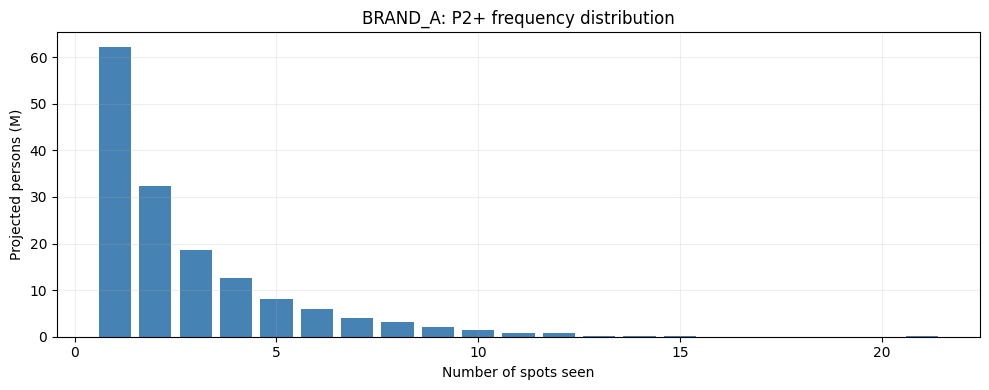

Share of impressions at 5+ exposures: 0.444


**Answer:** The average is 3.03 exposures, while people with five or more exposures receive 44.4% of all impressions. The mean alone hides the difference between light and heavy viewers; I would show the distribution alongside it.

In [ ]:
person_frequency = exposures.groupby("respondent_id").ad_airing_id.nunique().rename("frequency").to_frame()
person_frequency["monthly_weight"] = mw.reindex(person_frequency.index)
distribution = person_frequency.groupby("frequency").monthly_weight.sum()
distribution = distribution.reindex(range(1, int(person_frequency.frequency.max()) + 1), fill_value=0)
fig, ax = plt.subplots()
ax.bar(distribution.index, distribution / 1e6, color="steelblue")
ax.set(xlabel="Number of spots seen", ylabel="Projected persons (M)",
       title="BRAND_A: P2+ frequency distribution")
plt.tight_layout()
plt.show()
loyal_ids = person_frequency.index[person_frequency.frequency.ge(5)]
share_5plus = exposures.loc[exposures.respondent_id.isin(loyal_ids), "weight"].sum() / p2_imp
print("Share of impressions at 5+ exposures:", f"{share_5plus:.3f}")
answer(f"The average is {p2_freq:.2f} exposures, while people with five or more exposures receive "
       f"{share_5plus:.1%} of all impressions. The mean alone hides the difference between light "
       "and heavy viewers; I would show the distribution alongside it.")

**Answer:** The calculated interpretation appears above. The histogram uses monthly weights for persons, while the impressions share uses actual daily-weight impressions. These different weights mean the histogram average may differ slightly from GRPs/reach.

## Task 2.3 — On target?

What share of impressions reached A18–49? Compare it with approximately 42% of persons and identify the networks explaining the result.

In [ ]:
target_share = target_imp / p2_imp
print("Share of impressions on A18-49:", f"{target_share:.3f}")
delivery = spots.groupby("network_code")[["p2_impressions", "target_impressions"]].sum()
delivery["target_share"] = delivery.target_impressions / delivery.p2_impressions
delivery["campaign_impression_share"] = delivery.p2_impressions / p2_imp
delivery["contribution_to_gap_pp"] = (delivery.target_impressions - 0.42 * delivery.p2_impressions) / p2_imp * 100
display(delivery.reindex(NETWORKS).style.format(
    {"p2_impressions": "{:.0f}", "target_impressions": "{:.0f}", "target_share": "{:.3f}",
     "campaign_impression_share": "{:.3f}", "contribution_to_gap_pp": "{:.2f}"}))
direction = "under-delivers" if target_share < 0.42 else "over-delivers"
drivers = delivery.sort_values("contribution_to_gap_pp", ascending=target_share < 0.42).head(3).index
answer(f"A18–49 receives {target_share:.1%} of campaign impressions, versus about 42% of persons, "
       f"so the plan {direction} on target composition. The largest contributions to the gap "
       f"come from {', '.join(drivers)}. This compares audience mix, rather than the P2+ GRP guarantee.")

Share of impressions on A18-49: 0.194


,p2_impressions,target_impressions,target_share,campaign_impression_share,contribution_to_gap_pp
network_code,,,,,
CBS,88980316,13693421,0.154,0.212,-5.65
NBC,41435020,7833538,0.189,0.099,-2.29
ABC,94211430,16988998,0.180,0.225,-5.39
FOX,76255700,18440098,0.242,0.182,-3.24
FNC,57798841,2717037,0.047,0.138,-5.15
FX,8522567,5551130,0.651,0.020,0.47
BRAVO,5084258,2817365,0.554,0.012,0.16
HGTV,24657356,7554439,0.306,0.059,-0.67
FOOD,9481466,2991886,0.316,0.023,-0.24


**Answer:** A18–49 receives 19.4% of campaign impressions, versus about 42% of persons, so the plan under-delivers on target composition. The largest contributions to the gap come from CBS, ABC, FNC. This compares audience mix, rather than the P2+ GRP guarantee.

**Answer:** The table includes network impression shares, so a small network's age profile is not mistaken for a large contribution to the campaign result.

## Task 3.1 — Cost

Calculate total cost and CPM and CPP for P2+ and A18–49.

In [ ]:
cost = spots.cost_usd.sum()
p2_cpm = cost / p2_imp * 1000
target_cpm = cost / target_imp * 1000
p2_cpp = cost / p2_grps
target_cpp = cost / target_grps
print("Campaign cost (USD):", f"{cost:.0f}")
print("P2+ CPM (USD):", f"{p2_cpm:.2f}")
print("P2+ CPP (USD):", f"{p2_cpp:.0f}")
print("A18-49 CPM (USD):", f"{target_cpm:.2f}")
print("A18-49 CPP (USD):", f"{target_cpp:.0f}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


**Answer:** CPM = cost ÷ impressions × 1,000. CPP = cost ÷ GRPs. The same total campaign cost is divided by the delivery of each audience.

## Task 3.2 — By network

Report spots, cost, impressions and P2+ and A18–49 CPM by network. Where was the money spent? Which networks were cheapest for the target?

In [ ]:
network_cost = spots.groupby("network_code").agg(
    spots=("cost_usd", "size"), cost_USD=("cost_usd", "sum"),
    P2_impressions=("p2_impressions", "sum"), A18_49_impressions=("target_impressions", "sum"))
network_cost["P2_CPM_USD"] = network_cost.cost_USD / network_cost.P2_impressions.replace(0, np.nan) * 1000
network_cost["A18_49_CPM_USD"] = network_cost.cost_USD / network_cost.A18_49_impressions.replace(0, np.nan) * 1000
network_cost["cost_share"] = network_cost.cost_USD / cost
shown = network_cost.copy()
shown["P2_impressions_M"] = shown.pop("P2_impressions") / 1e6
shown["A18_49_impressions_M"] = shown.pop("A18_49_impressions") / 1e6
display(shown.reindex(NETWORKS).style.format(
    {"spots": "{:.0f}", "cost_USD": "{:.0f}", "P2_impressions_M": "{:.1f}", "A18_49_impressions_M": "{:.1f}",
     "P2_CPM_USD": "{:.2f}", "A18_49_CPM_USD": "{:.2f}", "cost_share": "{:.3f}"}))
top = network_cost.nlargest(3, "cost_USD")
cheap = network_cost.dropna(subset=["A18_49_CPM_USD"]).nsmallest(3, "A18_49_CPM_USD")
cheap_text = ", ".join(f"{n} (${r.A18_49_CPM_USD:.2f})" for n, r in cheap.iterrows())
answer(f"{', '.join(top.index)} have the largest budgets and together receive "
       f"{top.cost_USD.sum() / cost:.1%} of spending. The lowest observed target CPMs are "
       f"{cheap_text}. These compare impressions, including repeated exposures, rather than unique reach.")

,spots,cost_USD,P2_CPM_USD,A18_49_CPM_USD,cost_share,P2_impressions_M,A18_49_impressions_M
network_code,,,,,,,
CBS,22,1488700,16.73,108.72,0.201,89.0,13.7
NBC,16,796800,19.23,101.72,0.107,41.4,7.8
ABC,29,1625700,17.26,95.69,0.219,94.2,17.0
FOX,13,2434700,31.93,132.03,0.328,76.3,18.4
FNC,40,526300,9.11,193.70,0.071,57.8,2.7
FX,38,92200,10.82,16.61,0.012,8.5,5.6
BRAVO,33,49610,9.76,17.61,0.007,5.1,2.8
HGTV,39,230000,9.33,30.45,0.031,24.7,7.6
FOOD,33,96620,10.19,32.29,0.013,9.5,3.0


**Answer:** FOX, ABC, CBS have the largest budgets and together receive 74.8% of spending. The lowest observed target CPMs are FX ($16.61), BRAVO ($17.61), HGTV ($30.45). These compare impressions, including repeated exposures, rather than unique reach.

**Answer:** The cheapest target CPMs and main spending networks are listed above. Cost per impression and cost per newly reached person answer different questions.

## Task 3.3 — Guarantee

Was the guarantee of 150 P2+ GRPs met? Calculate make-good GRPs and their approximate value at campaign CPP.

In [ ]:
shortfall = max(150 - p2_grps, 0)
print("Guarantee met:", bool(p2_grps >= 150))
print("Make-good GRPs owed:", f"{shortfall:.1f}")
print("Value of make-goods (USD):", f"{shortfall * p2_cpp:.0f}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


**Answer:** Any positive shortfall below 150 P2+ GRPs is owed as make-goods. Its approximate value uses the campaign's P2+ CPP.

## Task 4 — Do networks add up?

Calculate P2+ reach for big networks, small networks and the whole campaign; overlap versus independence; incremental small-network reach and its cost. Explain the results.

In [ ]:
exp_network = exposures.merge(spots[["network_code"]], left_on="ad_airing_id", right_index=True, validate="many_to_one")
big_ids = set(exp_network.loc[exp_network.network_code.isin(BIG), "respondent_id"])
small_ids = set(exp_network.loc[exp_network.network_code.isin(SMALL), "respondent_id"])
big_reach = reach(big_ids)
small_reach = reach(small_ids)
whole_reach = reach(big_ids | small_ids)
overlap = reach(big_ids & small_ids)
independent = big_reach * small_reach / 100
added = whole_reach - big_reach
big_cost = spots.loc[spots.network_code.isin(BIG), "cost_usd"].sum()
small_cost = spots.loc[spots.network_code.isin(SMALL), "cost_usd"].sum()
small_cppoint = small_cost / added if added > 0 else np.inf
big_cppoint = big_cost / big_reach if big_reach > 0 else np.inf
print("Reach, big networks (%):", f"{big_reach:.1f}")
print("Reach, small networks (%):", f"{small_reach:.1f}")
print("Reach, whole campaign (%):", f"{whole_reach:.1f}")
print("Overlap (%):", f"{overlap:.1f}")
print("Overlap if independent (%):", f"{independent:.1f}")
print("Reach added by small networks (points):", f"{added:.1f}")
print("Cost per added reach point, small (USD):", f"{small_cppoint:.0f}")
print("Cost per reach point, big (USD):", f"{big_cppoint:.0f}")
assert np.isclose(whole_reach, big_reach + small_reach - overlap)
conditional = overlap / small_reach * 100 if small_reach else 0
relation = "more" if overlap > independent else "less"
explanation = ("Heavier TV viewers and shared viewing habits could explain the positive overlap."
               if overlap > independent else "Different viewing preferences could explain the lower overlap.")
relative_cost = "lower" if small_cppoint < big_cppoint else "higher"
answer(f"Adding the two reaches counts shared viewers twice. Of the people reached on small networks, "
       f"{conditional:.1f}% were also reached on big networks, versus {big_reach:.1f}% of all persons: "
       f"they were {relation} likely than average to be reached by big networks. {explanation} "
       f"Small networks added {added:.1f} points at a {relative_cost} cost per added point "
       "than the big-network average; that is the relevant efficiency comparison for P2+ reach.")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Adding the two reaches counts shared viewers twice. Of the people reached on small networks, 70.2% were also reached on big networks, versus 39.8% of all persons: they were more likely than average to be reached by big networks. Heavier TV viewers and shared viewing habits could explain the positive overlap. Small networks added 3.7 points at a lower cost per added point than the big-network average; that is the relevant efficiency comparison for P2+ reach.

**Answer:** Whole reach = big reach + small reach − overlap. The interpretation above compares marginal P2+ reach costs; it does not establish efficiency for A18–49 reach.

## Task 5 — How sure are we?

Count panelists per spot and report network medians; count zero-viewer spots. Compute median relative SE for big and small networks using SE = √[p(1−p)/n] × 100. Count W18–34 zero-cell spots and explain the limits.

In [ ]:
spots["panelists"] = exposures.groupby("ad_airing_id").respondent_id.nunique().reindex(spots.index, fill_value=0)
p = spots.p2_rating / 100
spots["SE_points"] = np.sqrt(p * (1 - p) / spots.broadcast_date.map(in_tab_n)) * 100
# SE/rating is undefined for a zero rating, so exclude those from relative medians.
spots["relative_SE"] = spots.SE_points / spots.p2_rating.replace(0, np.nan)
reliability = spots.groupby("network_code").agg(
    median_panelists=("panelists", "median"), median_relative_SE=("relative_SE", "median"),
    zero_spots=("panelists", lambda x: x.eq(0).sum()))
display(reliability.reindex(NETWORKS).style.format(
    {"median_panelists": "{:.1f}", "median_relative_SE": "{:.3f}", "zero_spots": "{:.0f}"}))
zeros = int(spots.panelists.eq(0).sum())
big_se = spots.loc[spots.network_code.isin(BIG), "relative_SE"].median()
small_se = spots.loc[spots.network_code.isin(SMALL), "relative_SE"].median()
women_counts = exposures.loc[exposures.respondent_id.isin(w1834_ids)].groupby("ad_airing_id").respondent_id.nunique().reindex(spots.index, fill_value=0)
women_zeros = int(women_counts.eq(0).sum())
print("Spots seen by no panelist:", zeros)
print("Median relative SE, big networks:", f"{big_se:.3f}")
print("Median relative SE, small networks:", f"{small_se:.3f}")
print("W18-34 zero-cell spots:", women_zeros)
answer(f"{zeros} spots have no observed P2+ panelist and therefore get a measured zero rating. "
       "That means no viewing was observed in this sample, not that the population audience was zero. "
       f"W18–34 has {women_zeros} zero-cell spots out of {len(spots)}; I would show the panel counts "
       "and avoid treating individual-spot demographic estimates as precise, preferably pooling airings. "
       "A zero rating also produces zero in this plug-in SE formula and must not be mistaken for certainty. "
       "Relative-SE medians exclude zero ratings (0/0 is undefined). Unequal weights and the panel design "
       "can make the real error larger than this simple-random-sample lower-bound approximation.")

,median_panelists,median_relative_SE,zero_spots
network_code,,,
CBS,69.0,0.113,0
NBC,68.5,0.115,0
ABC,57.0,0.123,0
FOX,145.0,0.080,0
FNC,31.0,0.164,0
FX,5.5,0.423,4
BRAVO,3.0,0.540,3
HGTV,11.0,0.301,0
FOOD,5.0,0.423,2


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** 10 spots have no observed P2+ panelist and therefore get a measured zero rating. That means no viewing was observed in this sample, not that the population audience was zero. W18–34 has 171 zero-cell spots out of 300; I would show the panel counts and avoid treating individual-spot demographic estimates as precise, preferably pooling airings. A zero rating also produces zero in this plug-in SE formula and must not be mistaken for certainty. Relative-SE medians exclude zero ratings (0/0 is undefined). Unequal weights and the panel design can make the real error larger than this simple-random-sample lower-bound approximation.

**Answer:** The calculated counts and interpretation appear above. Small-network ratings can depend on very few panelists, so a large projected audience does not imply a large sample.

## Bonus

Move the budget of any 20 spots to other networks and selling dayparts. Support a proposal to lower target CPM or raise reach with numbers (three or four sentences).

In [ ]:
# Choose the 20 least efficient observed target spots.
spots["target_CPM"] = spots.cost_usd / spots.target_impressions.replace(0, np.nan) * 1000
remove_ids = spots.target_CPM.fillna(np.inf).sort_values(ascending=False).head(20).index
removed = spots.loc[remove_ids]
budget = removed.cost_usd.sum()
inventory = spots.groupby(["network_code", "selling_daypart"]).agg(
    observed_spots=("cost_usd", "size"), total_cost=("cost_usd", "sum"),
    target_impressions=("target_impressions", "sum"))
inventory["price_per_30"] = inventory.total_cost / inventory.observed_spots
inventory["target_per_spot"] = inventory.target_impressions / inventory.observed_spots
inventory["target_CPM"] = inventory.total_cost / inventory.target_impressions.replace(0, np.nan) * 1000
source_networks = set(removed.network_code)
source_dayparts = set(removed.selling_daypart)
eligible = inventory.loc[
    ~inventory.index.get_level_values("network_code").isin(source_networks)
    & ~inventory.index.get_level_values("selling_daypart").isin(source_dayparts)].copy()
if eligible.empty:
    source_pairs = set(zip(removed.network_code, removed.selling_daypart))
    eligible = inventory.loc[[pair not in source_pairs for pair in inventory.index]].copy()
eligible = eligible.loc[eligible.target_impressions.gt(0) & eligible.price_per_30.le(budget)].copy()
assert not eligible.empty, "No alternative selling inventory within budget."
eligible["new_spots"] = np.floor(budget / eligible.price_per_30).astype(int)
eligible["new_target_impressions"] = eligible.new_spots * eligible.target_per_spot
best = eligible.sort_values("new_target_impressions", ascending=False).iloc[0]
network, daypart = best.name
purchase_cost = best.new_spots * best.price_per_30
new_cost = cost - budget + purchase_cost
new_target = target_imp - removed.target_impressions.sum() + best.new_target_impressions
new_cpm = new_cost / new_target * 1000
display(eligible.sort_values("new_target_impressions", ascending=False).head(5).style.format(
    {"observed_spots": "{:.0f}", "total_cost": "{:.0f}", "target_impressions": "{:.0f}",
     "price_per_30": "{:.0f}", "target_per_spot": "{:.0f}", "target_CPM": "{:.2f}",
     "new_spots": "{:.0f}", "new_target_impressions": "{:.0f}"}))
answer(
    f"I would move the ${budget:,.0f} budget of the 20 spots with the highest observed target CPM to {network}, {daypart}. "
    f"This inventory costs ${best.price_per_30:,.0f} per thirty-second spot and averaged {best.target_per_spot / 1e6:.2f} million A18–49 impressions across {int(best.observed_spots)} campaign spots. "
    f"The budget buys {int(best.new_spots)} spots with ${budget - purchase_cost:,.0f} unspent; using that observed average, the revised campaign target CPM is ${new_cpm:.2f}, compared with ${target_cpm:.2f} originally. "
    "This is a planning estimate assuming similar audiences and available rate-card inventory; I would check more airings before buying and would not infer extra unique reach from CPM alone."
)

**Answer:** I would move the $53,360 budget of the 20 spots with the highest observed target CPM to FOX, Run of Schedule. This inventory costs $16,300 per thirty-second spot and averaged 0.53 million A18–49 impressions across 1 campaign spots. The budget buys 3 spots with $4,460 unspent; using that observed average, the revised campaign target CPM is $89.71, compared with $91.53 originally. This is a planning estimate assuming similar audiences and available rate-card inventory; I would check more airings before buying and would not infer extra unique reach from CPM alone.

**Answer:** The four-sentence proposal above is generated from the observed prices and audiences. It is a forecast under stated assumptions, separate from measured campaign delivery.